# Supplementary Figure S6a. Split-sample correlation of trans-MaxPIP annotations

Pearson correlation between variant-level trans-MaxPIP annotations derived independently from two non-overlapping 50:50 donor splits, for TransMap-global, TransMap-local and TransMap-eGene. As in the source code (`Manu_Figures/Figure_Calibration.ipynb` cells 3-8, also `potential_artifact/Spit_sample_analysis.ipynb` cell 45), each correlation is computed only over 1000G variants whose annotation is non-zero in both splits (`n_variants_both_nonzero`: 17,979 global, 434,720 local, 840,535 eGene); correlations across scales are not computed and are shown as "-". Values are recomputed from the S-LDSC `.annot.gz` files and equal the saved `SLDSC_Spit_sample_annotation_correlation.rds` (0.79, 0.45, 0.47).

Input: `data/Figure_S6a_split_annotation_correlation.rds`.

In [1]:
library(ggplot2)
r <- readRDS("data/Figure_S6a_split_annotation_correlation.rds")
r

scale,n_variants_both_nonzero,n_split1_nonzero,n_split2_nonzero,pearson_r
<fct>,<int>,<int>,<int>,<dbl>
TransMap-eGene,840535,1962652,1837221,0.4724473
TransMap-local,434720,1769459,869037,0.4521367
TransMap-global,17979,157460,164429,0.7937106


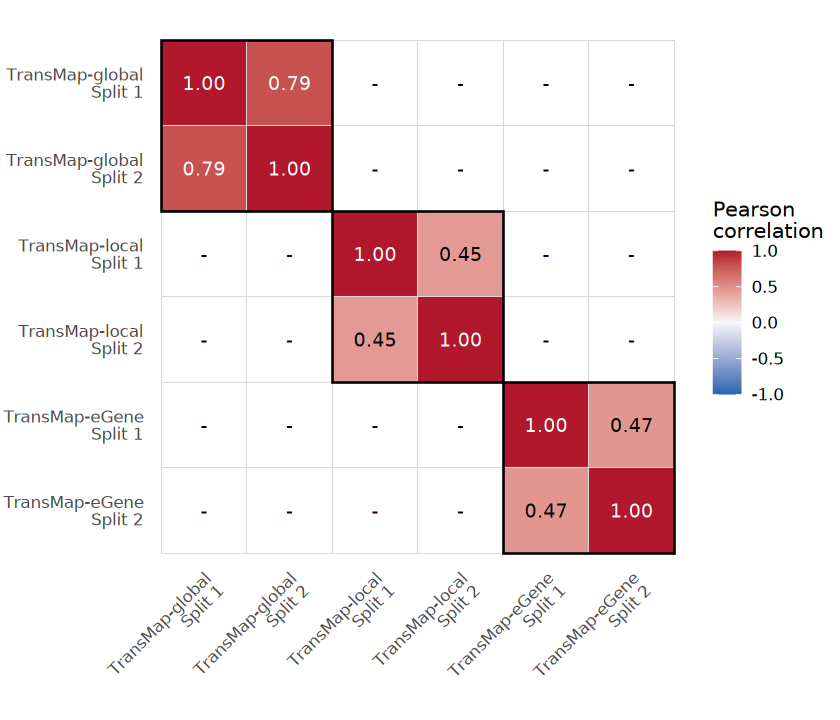

In [2]:
lv <- unlist(lapply(levels(r$scale), function(s) paste0(s, "\nSplit ", 1:2)))
grid <- expand.grid(row = lv, col = lv, stringsAsFactors = FALSE)
sc <- function(x) sub("\n.*", "", x)
grid$correlation <- ifelse(grid$row == grid$col, 1,
                           ifelse(sc(grid$row) == sc(grid$col), r$pearson_r[match(sc(grid$row), r$scale)], NA))
grid$label <- ifelse(is.na(grid$correlation), "-", sprintf("%.2f", grid$correlation))
grid$row <- factor(grid$row, levels = rev(lv)); grid$col <- factor(grid$col, levels = lv)
boxes <- data.frame(xmin = c(0.5, 2.5, 4.5), xmax = c(2.5, 4.5, 6.5), ymin = c(4.5, 2.5, 0.5), ymax = c(6.5, 4.5, 2.5))
p <- ggplot(grid, aes(x = col, y = row, fill = correlation)) +
  geom_tile(colour = "grey85") +
  geom_text(aes(label = label, colour = !is.na(correlation) & correlation >= 0.6), size = 4) +
  geom_rect(data = boxes, aes(xmin = xmin, xmax = xmax, ymin = ymin, ymax = ymax), inherit.aes = FALSE,
            fill = NA, colour = "black") +
  scale_fill_gradient2(low = "#2166AC", mid = "#F7F7F7", high = "#B2182B", midpoint = 0, limits = c(-1, 1),
                       na.value = "white", name = "Pearson\ncorrelation") +
  scale_colour_manual(values = c("TRUE" = "white", "FALSE" = "black"), guide = "none") +
  coord_fixed() + labs(x = NULL, y = NULL) +
  theme_minimal(base_size = 12) + theme(panel.grid = element_blank(), axis.text.x = element_text(angle = 45, hjust = 1))
options(repr.plot.width = 7, repr.plot.height = 6)
p